# Bước 1: Khám phá & làm sạch dữ liệu UIT-ViQuAD2.0

**Mục tiêu**
- Hiểu cấu trúc, kích thước và phân bố của dataset `taidng/UIT-ViQuAD2.0` (Vietnamese extractive QA, có câu hỏi không trả lời được).
- Audit lỗi nhãn (offset sai, Unicode không chuẩn, khoảng trắng lạ) **trước** khi làm sạch.
- Thống kê độ dài để chọn `max_length` và `doc_stride` cho bước fine-tune.
- Làm sạch có chính sách rõ ràng, audit lại **sau** khi làm sạch, kiểm tra data leakage.
- Lưu dữ liệu sạch (`data/processed/uit_viquad2_clean`) và `stats.json` cho các bước sau.

Notebook chạy từ thư mục `notebooks/`, helper nằm ở `src/data_clean.py`. Mọi hình lưu tại `outputs/figures/01_*.png`.

In [1]:
import sys, json, math, hashlib, random
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from datasets import load_dataset, Dataset, DatasetDict

# Project root: notebook is expected to run inside notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_clean import ISSUES, audit_row, clean_split, normalize_text

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

CACHE = ROOT / 'data' / 'hf_cache'
PROC = ROOT / 'data' / 'processed'
FIG = ROOT / 'outputs' / 'figures'
for p in (CACHE, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

STATS = {}  # key numbers, dumped to stats.json in section 7


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=120, bbox_inches='tight')
    plt.show()
    print('saved', FIG / name)


print('ROOT =', ROOT)

ROOT = D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA


D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ds = load_dataset('taidng/UIT-ViQuAD2.0', cache_dir=str(CACHE))
print(ds)
SPLITS = [s for s in ('train', 'validation', 'test') if s in ds]
RAW = {s: [dict(r) for r in ds[s]] for s in SPLITS}  # original rows kept untouched


def to_df(split, store=None):
    # Flat view of one split; defensive against missing/empty answer lists
    store = RAW if store is None else store
    recs = []
    for r in store[split]:
        a = r.get('answers') or {}
        t = list(a.get('text') or [])
        s = list(a.get('answer_start') or [])
        recs.append(dict(
            id=r.get('id'), title=r.get('title'),
            context=r.get('context') or '', question=r.get('question') or '',
            is_impossible=bool(r.get('is_impossible')), n_ans=len(t),
            ans_text=t[0] if t else None, ans_start=s[0] if s else None))
    return pd.DataFrame(recs)


DF = {s: to_df(s) for s in SPLITS}


def short(r):
    return {k: (v[:150] + '...' if isinstance(v, str) and len(v) > 150 else v) for k, v in r.items()}


ans_row = next((r for r in RAW['train'] if not r.get('is_impossible')), None)
imp_row = next((r for r in RAW['train'] if r.get('is_impossible')), None)
print('--- one answerable row (context truncated)')
print(short(ans_row) if ans_row else None)
print('--- one impossible row (context truncated)')
print(short(imp_row) if imp_row else None)

DatasetDict({
    train: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 28454
    })
    validation: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 3814
    })
    test: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 7301
    })
})


--- one answerable row (context truncated)
{'id': '0001-0001-0001', 'uit_id': 'uit_000001', 'title': 'Phạm Văn Đồng', 'context': 'Phạm Văn Đồng (1 tháng 3 năm 1906 – 29 tháng 4 năm 2000) là Thủ tướng đầu tiên của nước Cộng hòa Xã hội chủ nghĩa Việt Nam từ năm 1976 (từ năm 1981 gọ...', 'question': 'Tên gọi nào được Phạm Văn Đồng sử dụng khi làm Phó chủ nhiệm cơ quan Biện sự xứ tại Quế Lâm?', 'answers': {'text': ['Lâm Bá Kiệt'], 'answer_start': [507]}, 'is_impossible': False, 'plausible_answers': None}
--- one impossible row (context truncated)
{'id': '0001-0001-0004', 'uit_id': 'uit_000004', 'title': 'Phạm Văn Đồng', 'context': 'Phạm Văn Đồng (1 tháng 3 năm 1906 – 29 tháng 4 năm 2000) là Thủ tướng đầu tiên của nước Cộng hòa Xã hội chủ nghĩa Việt Nam từ năm 1976 (từ năm 1981 gọ...', 'question': 'Tên gọi nào được Phạm Văn Đồng sử dụng trước khi làm Phó chủ nhiệm cơ quan Biện sự xứ tại Quế Lâm?', 'answers': {'text': [], 'answer_start': []}, 'is_impossible': True, 'plausible_answers': {'tex

## 1. Tổng quan dataset

**Mục tiêu:** biết kích thước từng split, số context/title duy nhất, tỉ lệ câu hỏi không trả lời được (`is_impossible`) và số đáp án trên mỗi câu hỏi.

columns: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers']


,rows,unique_contexts,unique_titles,is_impossible_%,no_answer_list_%
train,28454.0,4101.0,138.0,32.39,32.39
validation,3814.0,557.0,19.0,30.44,30.44
test,7301.0,1241.0,48.0,0.00,100.00


Số đáp án trên mỗi câu hỏi (count):


,train,validation,test
n_answers,,,
0,9216,1161,7301
1,19238,1423,0
2,0,1048,0
3,0,182,0


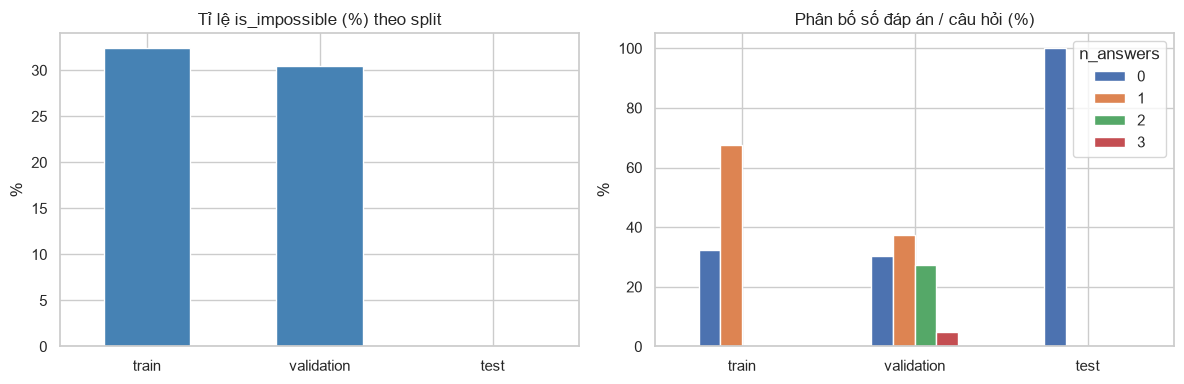

saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\outputs\figures\01_overview.png
train: 28454 câu hỏi, 4101 context duy nhất, 32.4% is_impossible, 0.0% có >1 đáp án
validation: 3814 câu hỏi, 557 context duy nhất, 30.4% is_impossible, 32.2% có >1 đáp án
test: 7301 câu hỏi, 1241 context duy nhất, 0.0% is_impossible, 0.0% có >1 đáp án


In [3]:
print('columns:', ds[SPLITS[0]].column_names)
overview = pd.DataFrame({
    s: {
        'rows': len(d),
        'unique_contexts': d.context.nunique(),
        'unique_titles': d.title.nunique(),
        'is_impossible_%': round(100 * d.is_impossible.mean(), 2),
        'no_answer_list_%': round(100 * (d.n_ans == 0).mean(), 2),
    } for s, d in DF.items()
}).T
display(overview)

nans = pd.DataFrame({s: DF[s].n_ans.value_counts().sort_index() for s in SPLITS}).fillna(0).astype(int)
nans.index.name = 'n_answers'
print('Số đáp án trên mỗi câu hỏi (count):')
display(nans)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratio = pd.Series({s: 100 * DF[s].is_impossible.mean() for s in SPLITS})
ratio.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Tỉ lệ is_impossible (%) theo split')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=0)
(nans / nans.sum() * 100).T.plot(kind='bar', ax=axes[1])
axes[1].set_title('Phân bố số đáp án / câu hỏi (%)')
axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=0)
savefig('01_overview.png')

STATS['overview'] = overview.to_dict()
for s in SPLITS:
    d = DF[s]
    print(f'{s}: {len(d)} câu hỏi, {d.context.nunique()} context duy nhất, '
          f'{100 * d.is_impossible.mean():.1f}% is_impossible, {100 * (d.n_ans > 1).mean():.1f}% có >1 đáp án')

### Nhận xét 1
- Kích thước split: train 28,454, validation 3,814, test 7,301.
- Tỉ lệ `is_impossible` (NoAns): train 32.39%, validation 30.44% (tương đương nhau), test 0%. Vẫn nên báo cáo metric riêng cho HasAns/NoAns.
- Validation có nhiều đáp án / câu hỏi (1,230 dòng, 32.25%, là nhiều reference hợp lệ), train không có. Khi tính EM/F1 phải lấy max trên các đáp án.
- `test` có `answers` rỗng ở cả 7,301 dòng: HF test split là tập không có nhãn, không thể tính EM/F1 trên đó. Xem mục 9 để chia lại train/dev/test.

## 2. TRƯỚC khi làm sạch: audit

**Mục tiêu:** đếm các lỗi dữ liệu trên cả 3 split bằng `audit_row`:
- `offset_mismatch`: `context[start:start+len(text)] != text`.
- `not_nfc`, `has_double_space`, `has_nbsp_or_zerowidth`: lỗi Unicode / khoảng trắng (tiếng Việt dễ bị lẫn dạng tổ hợp NFD).
- Các lỗi logic nhãn: `answerable_without_answer`, `impossible_with_answer`, `empty_answer_text`, `empty_question`, `empty_context`; `multiple_answers` chỉ là thông tin.

In [4]:
def audit_split(rows):
    return pd.DataFrame([audit_row(r) for r in rows], columns=list(ISSUES))


def count_table(FL):
    return pd.DataFrame({s: FL[s].sum() for s in SPLITS}).astype(int)


def fmt_table(c, store):
    n = pd.Series({s: len(store[s]) for s in SPLITS})
    return c.astype(str) + ' (' + c.div(n, axis=1).mul(100).round(2).astype(str) + '%)'


FL_BEFORE = {s: audit_split(RAW[s]) for s in SPLITS}
before_cnt = count_table(FL_BEFORE)
print('Audit TRƯỚC khi làm sạch: số dòng (và %) mỗi lỗi')
display(fmt_table(before_cnt, RAW))
STATS['audit_before'] = before_cnt.to_dict()

Audit TRƯỚC khi làm sạch: số dòng (và %) mỗi lỗi


,train,validation,test
offset_mismatch,154 (0.54%),22 (0.58%),0 (0.0%)
empty_answer_text,0 (0.0%),0 (0.0%),0 (0.0%)
not_nfc,25 (0.09%),0 (0.0%),0 (0.0%)
has_double_space,65 (0.23%),5 (0.13%),48 (0.66%)
has_nbsp_or_zerowidth,10 (0.04%),0 (0.0%),0 (0.0%)
multiple_answers,0 (0.0%),1230 (32.25%),0 (0.0%)
answerable_without_answer,0 (0.0%),0 (0.0%),7301 (100.0%)
impossible_with_answer,0 (0.0%),0 (0.0%),0 (0.0%)
empty_question,0 (0.0%),0 (0.0%),0 (0.0%)
empty_context,0 (0.0%),0 (0.0%),0 (0.0%)


In [5]:
def show_example(r, issue):
    a = r.get('answers') or {}
    ctx = r.get('context') or ''
    print('  id =', r.get('id'), '| Q:', repr((r.get('question') or '')[:200]))
    if issue == 'offset_mismatch':
        for t, s in zip(a.get('text') or [], a.get('answer_start') or []):
            print('    answer', repr(t[:200]), '@', s, '-> context slice', repr(ctx[s:s + len(t)][:200]))
    else:
        print('    context[:200]:', repr(ctx[:200]))
        print('    answers:', repr(str(a)[:200]))


for issue in ISSUES:
    if before_cnt.loc[issue].sum() == 0:
        continue
    print('=====', issue, '=====')
    shown = 0
    for s in SPLITS:
        for i in np.flatnonzero(FL_BEFORE[s][issue].values.astype(bool))[:3 - shown]:
            print('[%s]' % s)
            show_example(RAW[s][i], issue)
            shown += 1
        if shown >= 3:
            break

===== offset_mismatch =====
[train]
  id = 0004-0002-0003 | Q: 'Để máy tính có thể hiểu và thực thi các chương trình được viết bằng ngôn ngữ bậc cao thì cần các công cụ phụ trợ nào?'
    answer 'các công cụ phụ trợ như trình biên dịch, trình hợp dịch hay trình liên kết' @ 174 -> context slice ' các công cụ phụ trợ như trình biên dịch, trình hợp dịch hay trình liên kế'
[train]
  id = 0004-0005-0003 | Q: 'Điểm nào cho thấy không phải máy tính hay chỉ thị đơn lẻ đều có toán hạng hiện?'
    answer 'Một máy tính thanh chứa có sự kết hợp giữa toán hạng trái và kết quả tính toán lưu trong một thanh chứa ẩn đối với hầu hết các chỉ thị đại số' @ 82 -> context slice ' Một máy tính thanh chứa có sự kết hợp giữa toán hạng trái và kết quả tính toán lưu trong một thanh chứa ẩn đối với hầu hết các chỉ thị đại s'
[train]
  id = 0006-0002-0001 | Q: 'Khi nào thì có con người xuất hiện ở Nhật Bản?'
    answer 'thời Thượng kỳ đồ đá cũ' @ 70 -> context slice ' thời Thượng kỳ đồ đá c'
===== not_nfc =====
[t

### Nhận xét 2
- Lỗi có count > 0: `offset_mismatch` = 154 dòng train, 22 validation, 0 test; `not_nfc` 25 (train); `has_double_space` 65 train / 5 validation / 48 test; `has_nbsp_or_zerowidth` 10 (train). Đều nhỏ (< 0.7% mỗi split).
- `multiple_answers` = 1,230 dòng validation (bình thường: nhiều reference), không phải lỗi; cần xử lý nhiều đáp án khi đánh giá.
- `answerable_without_answer` = 7,301 dòng test: do test không có nhãn, không phải lỗi dữ liệu.
- `impossible_with_answer` = 0 nên không có nhãn mâu thuẫn.

## 3. Thống kê độ dài TRƯỚC khi làm sạch

**Mục tiêu:** chọn `max_length`, `doc_stride`. Dùng tokenizer `xlm-roberta-base` (fast) để đếm token; với PhoBERT chỉ dùng số từ (whitespace) làm proxy vì PhoBERT cần word segmentation riêng (không dùng ở bước này).

Phân tích trên **train**. Context được lấy mẫu tối đa 5000 context duy nhất (seed cố định); các cặp (question, context) được ước lượng trên những context đã lấy mẫu; tất cả question đều được tokenize.

Công thức ước lượng số window (tokens, không tính special tokens của context):
- `budget = max_length - q_len - 4` (4 = special tokens `<s> q </s></s> ... </s>` của XLM-R)
- `windows = 1` nếu `c_len <= budget`, ngược lại `windows = 1 + ceil((c_len - budget) / max(budget - doc_stride, 1))`

Đây là ước lượng gần đúng, tokenizer thật có thể lệch vài window.

In [6]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained('xlm-roberta-base')


def count_tokens(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], add_special_tokens=False)['input_ids']
        out.extend(len(x) for x in enc)
    return out


TR = DF['train'].copy()
rng = np.random.RandomState(SEED)
uctx = TR.context.drop_duplicates().tolist()
pick = rng.choice(len(uctx), size=min(5000, len(uctx)), replace=False)
ctx_sample = [uctx[i] for i in pick]
ctx_tok = dict(zip(ctx_sample, count_tokens(ctx_sample)))

TR['q_tok'] = count_tokens(TR.question.tolist())
TR['q_words'] = TR.question.str.split().str.len()
ctx_len = pd.DataFrame({
    'c_tok': [ctx_tok[c] for c in ctx_sample],
    'c_words': [len(c.split()) for c in ctx_sample],
})

has = TR[(TR.n_ans > 0) & TR.ans_start.notna()].copy()
has['a_words'] = has.ans_text.str.split().str.len()
has['rel_start'] = has.ans_start / has.context.str.len().clip(lower=1)

pairs = TR[TR.context.isin(ctx_tok)].copy()
pairs['c_tok'] = pairs.context.map(ctx_tok)
print(f'unique train contexts: {len(uctx)}, sampled: {len(ctx_sample)}')
print(f'train questions tokenized: {len(TR)}, pairs in sampled contexts: {len(pairs)}, answerable rows: {len(has)}')

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (556 > 512). Running this sequence through the model will result in indexing errors


unique train contexts: 4101, sampled: 4101
train questions tokenized: 28454, pairs in sampled contexts: 28454, answerable rows: 19238


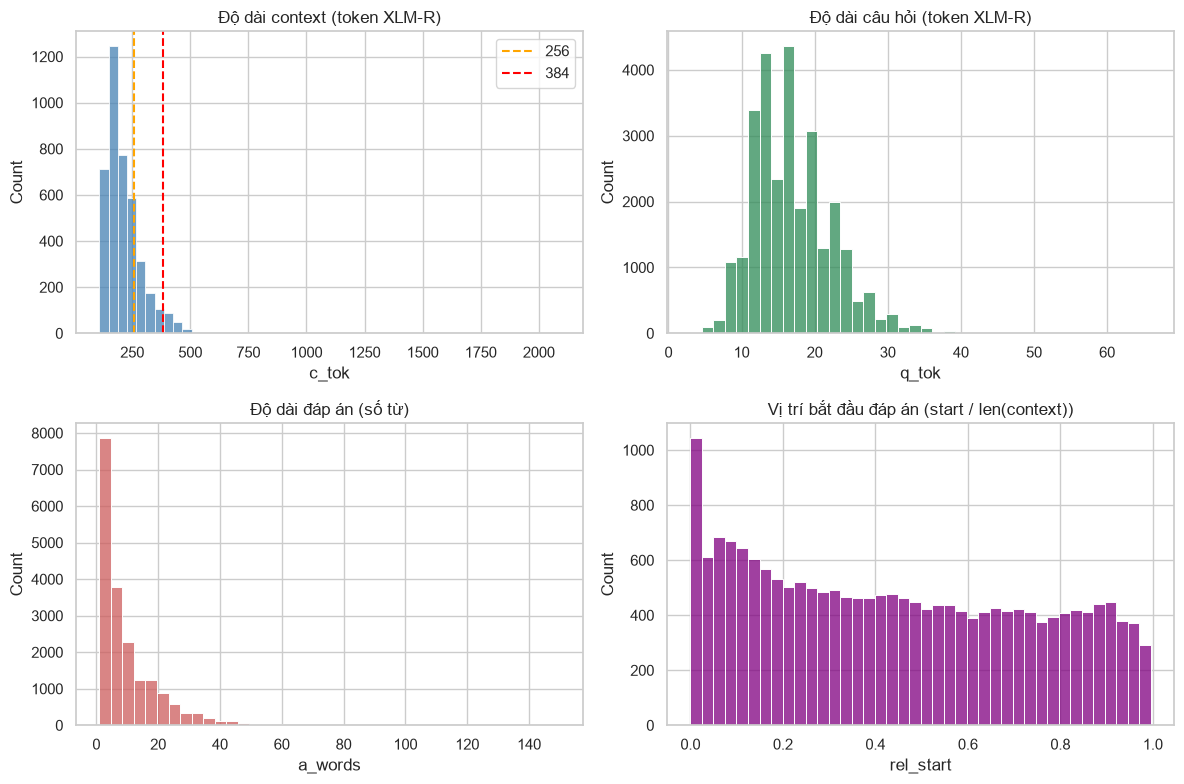

saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\outputs\figures\01_lengths_before.png


,context_tokens,context_words,question_tokens,answer_words,answer_rel_start
count,4101.000,4101.000,28454.000,19238.000,19238.000
mean,215.486,178.983,16.964,9.954,0.441
std,86.339,70.256,5.405,10.586,0.295
min,109.000,88.000,3.000,1.000,0.000
50%,192.000,160.000,16.000,6.000,0.418
90%,317.000,265.000,24.000,24.000,0.872
95%,374.000,311.000,27.000,31.000,0.926
99%,474.000,404.000,33.000,48.000,0.978
max,2091.000,1537.000,66.000,150.000,0.996


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(ctx_len.c_tok, bins=50, ax=axes[0, 0], color='steelblue')
axes[0, 0].axvline(256, color='orange', ls='--', label='256')
axes[0, 0].axvline(384, color='red', ls='--', label='384')
axes[0, 0].legend()
axes[0, 0].set_title('Độ dài context (token XLM-R)')
sns.histplot(TR.q_tok, bins=40, ax=axes[0, 1], color='seagreen')
axes[0, 1].set_title('Độ dài câu hỏi (token XLM-R)')
sns.histplot(has.a_words, bins=40, ax=axes[1, 0], color='indianred')
axes[1, 0].set_title('Độ dài đáp án (số từ)')
sns.histplot(has.rel_start, bins=40, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Vị trí bắt đầu đáp án (start / len(context))')
savefig('01_lengths_before.png')

q = [.5, .9, .95, .99]
len_stats = pd.DataFrame({
    'context_tokens': ctx_len.c_tok.describe(percentiles=q),
    'context_words': ctx_len.c_words.describe(percentiles=q),
    'question_tokens': TR.q_tok.describe(percentiles=q),
    'answer_words': has.a_words.describe(percentiles=q),
    'answer_rel_start': has.rel_start.describe(percentiles=q),
}).round(3)
display(len_stats)
STATS['length_stats_before'] = len_stats.to_dict()

In [8]:
def n_windows(q_len, c_len, max_len, stride=128):
    budget = np.maximum(max_len - q_len - 4, 1)
    step = np.maximum(budget - stride, 1)
    return np.where(c_len <= budget, 1, 1 + np.ceil((c_len - budget) / step)).astype(int)


rows = []
for L in (256, 384):
    total = pairs.q_tok.values + pairs.c_tok.values + 4
    w = n_windows(pairs.q_tok.values, pairs.c_tok.values, L)
    rows.append({
        'max_length': L,
        'pct_pairs_over': round(100 * float((total > L).mean()), 2),
        'mean_windows': round(float(w.mean()), 3),
        'max_windows': int(w.max()),
        'est_total_windows_train': int(round(float(w.mean()) * len(TR))),
    })
win_tbl = pd.DataFrame(rows).set_index('max_length')
display(win_tbl)

# Answer end beyond the first 384 tokens = lost if we only truncate (no sliding window)
ha = has[has.context.isin(ctx_tok)]
ha = ha.sample(min(5000, len(ha)), random_state=SEED)
end_tok = count_tokens([c[:int(s) + len(t)] for c, s, t in zip(ha.context, ha.ans_start, ha.ans_text)])
beyond384 = 100 * float((ha.q_tok.values + np.array(end_tok) + 3 > 384).mean())
print(f'Đáp án (HasAns) có điểm kết thúc vượt token 384 nếu chỉ truncate: {beyond384:.2f}% (mẫu {len(ha)} dòng)')
for L in (256, 384):
    print(f'max_length={L}: {win_tbl.loc[L, "pct_pairs_over"]:.2f}% cặp vượt giới hạn, '
          f'trung bình {win_tbl.loc[L, "mean_windows"]:.3f} window/cặp')
STATS['windows'] = win_tbl.to_dict()
STATS['answer_end_beyond_384_pct'] = beyond384

,pct_pairs_over,mean_windows,max_windows,est_total_windows_train
max_length,,,,
256,30.95,1.420,22,40396
384,6.14,1.068,9,30399


Đáp án (HasAns) có điểm kết thúc vượt token 384 nếu chỉ truncate: 0.98% (mẫu 5000 dòng)
max_length=256: 30.95% cặp vượt giới hạn, trung bình 1.420 window/cặp
max_length=384: 6.14% cặp vượt giới hạn, trung bình 1.068 window/cặp


### Nhận xét 3
- Context median 192 token, p95 374, p99 474, max 2091; câu hỏi ngắn (median 16 token, p99 33), nên phần lớn ngân sách `max_length` dành cho context.
- Với `max_length=384`, 6.14% cặp cần >1 window (~30.4k window train, TB 1.068, max 9); với 256 là 30.95% (~40.4k window, TB 1.42, max 22). Dùng sliding window (`doc_stride=128`) thay vì truncate; truncate ở 384 sẽ mất 0.98% đáp án.
- Đáp án ngắn: median 6 từ, p95 31, p99 48, max 150 => `max_answer_length` nên nâng lên ~50-64 token ở bước 4. Vị trí bắt đầu đáp án (`answer_rel_start`) lệch về phần đầu context, nhưng vẫn có đáp án ở xa nên cần sliding window.
- Lưu ý: số token PhoBERT sẽ khác (cần word segmentation, BPE khác) nên 256/384 ở đây chỉ là ước lượng bằng XLM-R.

## 4. Làm sạch

**Mục tiêu:** chuẩn hoá văn bản (NFC, bỏ zero-width, nbsp thành space, gộp khoảng trắng) và **tính lại `answer_start`** trong context mới.

**Chính sách**
- Train: loại dòng có câu hỏi/context rỗng, dòng HasAns không có đáp án, hoặc đáp án không tìm lại được trong context sau chuẩn hoá (`dropped_*`). Lý do: nhãn sai thì loss sai, mô hình học vị trí sai.
- Validation/test: **không bao giờ loại mẫu** (ghi nhận `*_kept`, giữ nguyên đáp án gốc) để tập đánh giá còn nguyên và so sánh công bằng với các công bố khác.
- Khi đáp án xuất hiện nhiều lần trong context, chọn lần xuất hiện gần nhất với offset gốc (đã ánh xạ qua chuẩn hoá).
- `plausible_answers` xử lý theo cách tương tự, bỏ lặng lẽ nếu không tìm thấy.

In [9]:
CLEAN, ACT = {}, {}
for s in SPLITS:
    CLEAN[s], ACT[s] = clean_split(RAW[s], is_train=(s == 'train'))

act_df = pd.DataFrame({s: dict(c) for s, c in ACT.items()}).fillna(0).astype(int)
print('Số lần mỗi action (theo split):')
display(act_df)

for s in SPLITS:
    dropped = len(RAW[s]) - len(CLEAN[s])
    kept_issue = sum(v for k, v in ACT[s].items() if k.endswith('_kept'))
    print(f'{s}: trước {len(RAW[s])} -> sau {len(CLEAN[s])} | loại {dropped} dòng | dòng giữ lại nhưng còn lỗi (val/test): {kept_issue}')
STATS['actions'] = {s: dict(c) for s, c in ACT.items()}

Số lần mỗi action (theo split):


,train,validation,test
normalized_question,98,7,47
offset_fixed,158,22,0
normalized_context,10,0,28
no_answer_kept,0,0,7301


train: trước 28454 -> sau 28454 | loại 0 dòng | dòng giữ lại nhưng còn lỗi (val/test): 0
validation: trước 3814 -> sau 3814 | loại 0 dòng | dòng giữ lại nhưng còn lỗi (val/test): 0
test: trước 7301 -> sau 7301 | loại 0 dòng | dòng giữ lại nhưng còn lỗi (val/test): 7301


### Nhận xét 4
- Số dòng train bị loại: 0 (0%) nên phân bố không đổi; không split nào bị loại dòng.
- `offset_fixed`: train 158, validation 22 (nhãn lệch đã được tính lại offset). Ngoài ra `normalized_question` train 98 / validation 7, `normalized_context` train 10.
- Validation: không có dòng `unfixable_kept` (mọi offset sửa được), nên không có trần metric do nhãn hỏng. Test: 7,301 dòng `no_answer_kept` chỉ vì không có nhãn.

## 5. SAU khi làm sạch: audit lại và so sánh

**Mục tiêu:** xác nhận lỗi offset/NFC/khoảng trắng về ~0 (train phải đúng 0 `offset_mismatch`), so sánh trước-sau theo từng lỗi, kích thước split và tỉ lệ `is_impossible`.

In [10]:
FL_AFTER = {s: audit_split(CLEAN[s]) for s in SPLITS}
after_cnt = count_table(FL_AFTER)
print('Audit SAU khi làm sạch:')
display(fmt_table(after_cnt, CLEAN))

recs = []
for issue in ISSUES:
    for s in SPLITS:
        recs.append({'issue': issue, 'split': s,
                     'before': int(before_cnt.loc[issue, s]), 'after': int(after_cnt.loc[issue, s])})
cmp = pd.DataFrame(recs)
cmp['delta'] = cmp['after'] - cmp['before']
display(cmp.pivot(index='issue', columns='split', values=['before', 'after', 'delta']).loc[list(ISSUES)])

n_bad = int(after_cnt.loc['offset_mismatch', 'train'])
if n_bad == 0:
    print('OK: train sau làm sạch có offset_mismatch == 0')
else:
    print(f'CẢNH BÁO: train sau làm sạch còn {n_bad} dòng offset_mismatch, cần kiểm tra lại clean_row')
STATS['audit_after'] = after_cnt.to_dict()

Audit SAU khi làm sạch:


,train,validation,test
offset_mismatch,0 (0.0%),0 (0.0%),0 (0.0%)
empty_answer_text,0 (0.0%),0 (0.0%),0 (0.0%)
not_nfc,0 (0.0%),0 (0.0%),0 (0.0%)
has_double_space,0 (0.0%),0 (0.0%),0 (0.0%)
has_nbsp_or_zerowidth,0 (0.0%),0 (0.0%),0 (0.0%)
multiple_answers,0 (0.0%),1230 (32.25%),0 (0.0%)
answerable_without_answer,0 (0.0%),0 (0.0%),7301 (100.0%)
impossible_with_answer,0 (0.0%),0 (0.0%),0 (0.0%)
empty_question,0 (0.0%),0 (0.0%),0 (0.0%)
empty_context,0 (0.0%),0 (0.0%),0 (0.0%)


before                  after                  delta                 
split                       test train validation  test train validation  test train validation
issue                                                                                          
offset_mismatch                0   154         22     0     0          0     0  -154        -22
empty_answer_text              0     0          0     0     0          0     0     0          0
not_nfc                        0    25          0     0     0          0     0   -25          0
has_double_space              48    65          5     0     0          0   -48   -65         -5
has_nbsp_or_zerowidth          0    10          0     0     0          0     0   -10          0
multiple_answers               0     0       1230     0     0       1230     0     0          0
answerable_without_answer   7301     0          0  7301     0          0     0     0          0
impossible_with_answer         0     0          0     0     0          0     0     0          0
empty_question                 0     0          0     0     0          0     0     0          0
empty_context                  0     0          0     0     0          0     0     0          0

OK: train sau làm sạch có offset_mismatch == 0


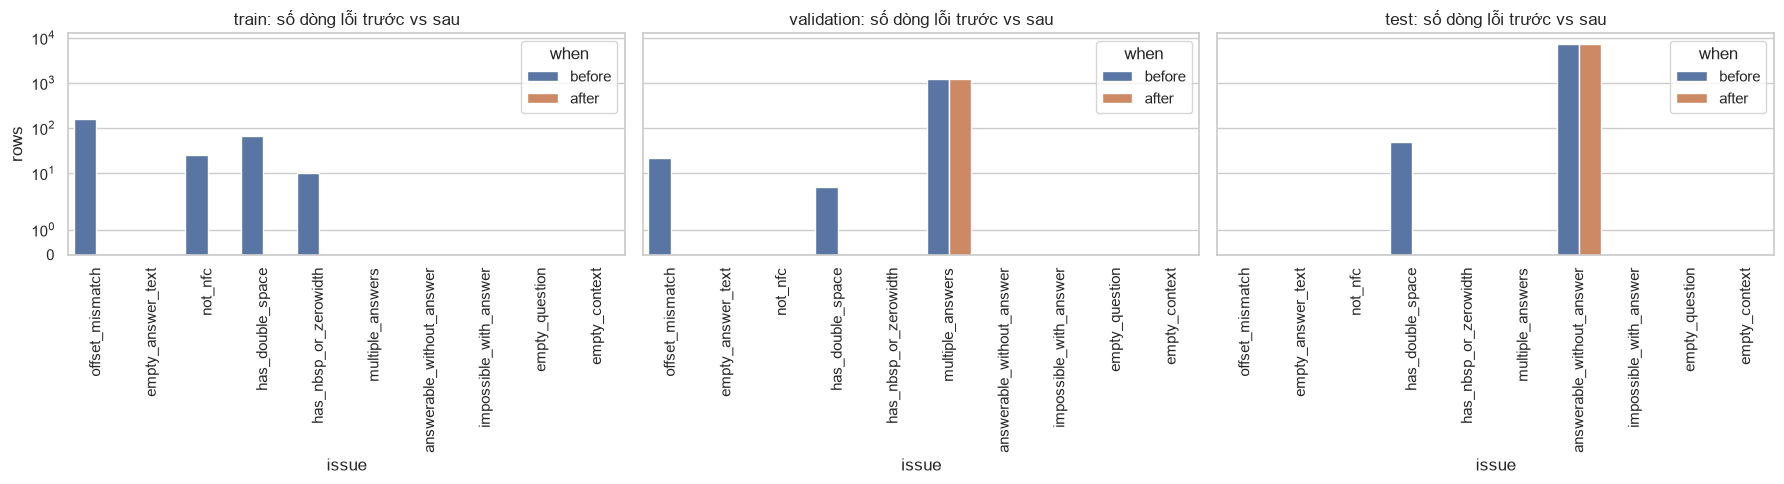

saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\outputs\figures\01_audit_before_after.png


,rows_before,rows_after,impossible_%_before,impossible_%_after,rows_delta
train,28454,28454,32.39,32.39,0
validation,3814,3814,30.44,30.44,0
test,7301,7301,0.00,0.00,0


In [11]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6 * len(SPLITS), 5), sharey=True)
axes = np.atleast_1d(axes)
for ax, s in zip(axes, SPLITS):
    sub = cmp[cmp.split == s].melt(id_vars='issue', value_vars=['before', 'after'],
                                   var_name='when', value_name='rows')
    sns.barplot(data=sub, x='issue', y='rows', hue='when', ax=ax)
    ax.set_yscale('symlog')
    ax.set_title(f'{s}: số dòng lỗi trước vs sau')
    ax.tick_params(axis='x', rotation=90)
savefig('01_audit_before_after.png')


def imp_pct(rows):
    return round(100 * float(np.mean([bool(r.get('is_impossible')) for r in rows])), 2) if rows else float('nan')


size_tbl = pd.DataFrame({
    'rows_before': {s: len(RAW[s]) for s in SPLITS},
    'rows_after': {s: len(CLEAN[s]) for s in SPLITS},
    'impossible_%_before': {s: imp_pct(RAW[s]) for s in SPLITS},
    'impossible_%_after': {s: imp_pct(CLEAN[s]) for s in SPLITS},
})
size_tbl['rows_delta'] = size_tbl.rows_after - size_tbl.rows_before
display(size_tbl)
STATS['sizes'] = size_tbl.to_dict()

### Nhận xét 5
- Kết quả: mọi lỗi về 0 trên cả 3 split (`offset_mismatch` = 0, `not_nfc` = 0, `has_double_space` = 0, `has_nbsp_or_zerowidth` = 0), kể cả validation/test.
- Chỉ còn 2 mục khác 0, đều có chủ đích: `multiple_answers` validation = 1,230 (không đổi, không phải lỗi) và `answerable_without_answer` test = 7,301 (test không có nhãn).
- Tỉ lệ `is_impossible` trước/sau không đổi vì không dòng nào bị loại.

## 6. Phân tích bổ sung (train sau làm sạch)

**Mục tiêu:** (a) loại câu hỏi qua từ nghi vấn đầu câu, (b) độ dài đáp án HasAns và `plausible_answers` của NoAns, (c) kiểm tra rò rỉ dữ liệu: context trùng giữa train và validation/test (băm md5 của context đã chuẩn hoá).

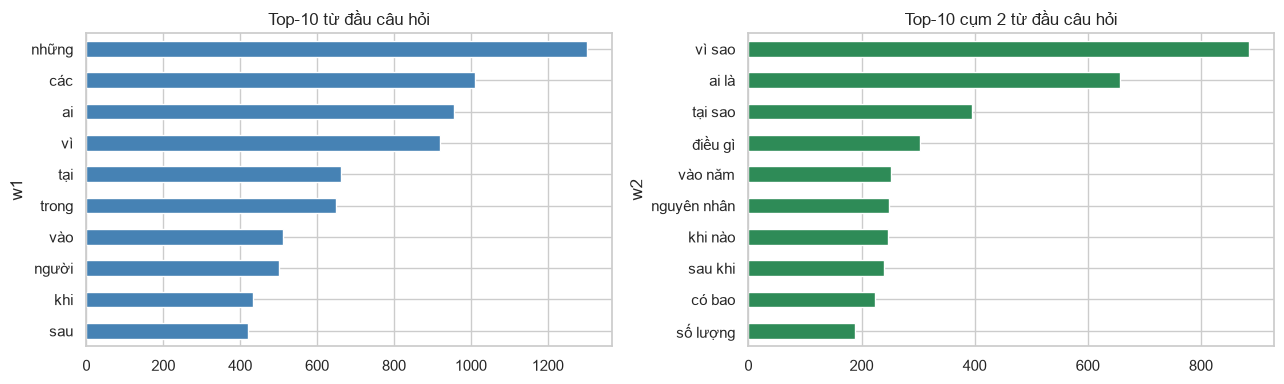

saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\outputs\figures\01_question_words.png


,first_word,count,first_two_words,count_2
0,những,1302,vì sao,885
1,các,1010,ai là,657
2,ai,957,tại sao,395
3,vì,920,điều gì,304
4,tại,663,vào năm,253
5,trong,649,nguyên nhân,248
6,vào,511,khi nào,247
7,người,500,sau khi,240
8,khi,434,có bao,224
9,sau,421,số lượng,188


Top-10 cụm 2 từ chiếm 12.8% câu hỏi train


In [12]:
CT = to_df('train', CLEAN)
words = CT.question.str.lower().str.split()
CT['w1'] = words.str[0]
CT['w2'] = words.str[:2].str.join(' ')
top1 = CT.w1.value_counts().head(10)
top2 = CT.w2.value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top1.iloc[::-1].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top-10 từ đầu câu hỏi')
top2.iloc[::-1].plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Top-10 cụm 2 từ đầu câu hỏi')
savefig('01_question_words.png')
display(pd.DataFrame({'first_word': top1.index, 'count': top1.values,
                      'first_two_words': top2.index, 'count_2': top2.values}))
print(f'Top-10 cụm 2 từ chiếm {100 * top2.sum() / len(CT):.1f}% câu hỏi train')
STATS['top_question_words'] = top2.to_dict()

q_words               c_words               
                count   mean median   count    mean median
is_impossible                                             
False           19238  14.61   14.0   19238  180.39  161.0
True             9216  14.72   14.0    9216  181.06  162.0

,value
"NoAns rows (train, sau làm sạch)",9216.00
NoAns có >=1 plausible answer,9215.00
tỉ lệ có plausible (%),99.99
số plausible trung bình,1.00


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
HasAns answer,19238.0,9.95,10.59,1.0,3.0,6.0,14.0,150.0
NoAns plausible,9215.0,9.75,10.56,1.0,3.0,6.0,13.0,122.0


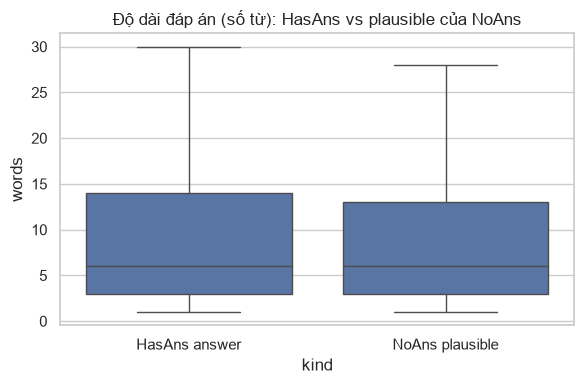

saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\outputs\figures\01_answer_len_vs_hasans.png


In [13]:
CT['q_words'] = CT.question.str.split().str.len()
CT['c_words'] = CT.context.str.split().str.len()
display(CT.groupby('is_impossible')[['q_words', 'c_words']].agg(['count', 'mean', 'median']).round(2))

has_words = CT[CT.n_ans > 0].ans_text.str.split().str.len()
imp_rows = [r for r in CLEAN['train'] if r.get('is_impossible')]
plaus_texts = [list((r.get('plausible_answers') or {}).get('text') or []) for r in imp_rows]
n_plaus = pd.Series([len(t) for t in plaus_texts])
plaus_words = pd.Series([len(t[0].split()) for t in plaus_texts if t])

plaus_tbl = pd.Series({
    'NoAns rows (train, sau làm sạch)': len(imp_rows),
    'NoAns có >=1 plausible answer': int((n_plaus > 0).sum()),
    'tỉ lệ có plausible (%)': round(100 * float((n_plaus > 0).mean()), 2) if len(n_plaus) else float('nan'),
    'số plausible trung bình': round(float(n_plaus.mean()), 3) if len(n_plaus) else float('nan'),
})
display(plaus_tbl.to_frame('value'))

kinds = pd.concat([pd.DataFrame({'kind': 'HasAns answer', 'words': has_words.values}),
                   pd.DataFrame({'kind': 'NoAns plausible', 'words': plaus_words.values})])
display(kinds.groupby('kind').words.describe().round(2))
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=kinds, x='kind', y='words', ax=ax, showfliers=False)
ax.set_title('Độ dài đáp án (số từ): HasAns vs plausible của NoAns')
savefig('01_answer_len_vs_hasans.png')
STATS['plausible'] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in plaus_tbl.items()}

In [14]:
def row_hash(r):
    return hashlib.md5(normalize_text(r.get('context') or '').encode('utf-8')).hexdigest()


H = {s: [row_hash(r) for r in CLEAN[s]] for s in SPLITS}
train_set = set(H['train'])
leak_rows = []
for s in SPLITS:
    if s == 'train':
        continue
    hs = H[s]
    shared_rows = sum(h in train_set for h in hs)
    leak_rows.append({
        'split': s,
        'unique_contexts': len(set(hs)),
        'contexts_shared_with_train': len(set(hs) & train_set),
        'rows_with_shared_context': shared_rows,
        'rows_shared_%': round(100 * shared_rows / max(len(hs), 1), 2),
    })
leak = pd.DataFrame(leak_rows)
display(leak)
if 'validation' in H and 'test' in H:
    print('contexts chung validation & test:', len(set(H['validation']) & set(H['test'])))
STATS['leakage'] = leak.to_dict('records')

,split,unique_contexts,contexts_shared_with_train,rows_with_shared_context,rows_shared_%
0,validation,557,0,0,0.00
1,test,1241,454,2143,29.35


contexts chung validation & test: 134


### Nhận xét 6
- Câu hỏi đa dạng loại: top-10 cụm 2 từ đầu câu chỉ chiếm một phần câu hỏi train (xem dòng in `Top-10 cụm 2 từ chiếm ...%` ở output phía trên), không thiên hẳn về vài loại.
- Đáp án HasAns ngắn (median 6 từ). Train có 9,216 dòng NoAns, 99.99% có plausible answer; câu hỏi NoAns là dạng adversarial (rất giống câu hỏi HasAns, chỉ khác chi tiết nhỏ), khó hơn nhiều.
- Rò rỉ: validation dùng chung 0/557 context với train (sạch). Test dùng chung 454/1,241 context với train (2,143 dòng, 29.35%), nên điểm trên test (nếu có nhãn) sẽ lạc quan hơn. Validation và test chung 134 context. Không loại bỏ, nhưng cần ghi chú; xem mục 9.

## 7. Lưu dữ liệu sạch

**Mục tiêu:** lưu `DatasetDict` đã làm sạch bằng `save_to_disk` và các số liệu chính vào `stats.json` để các bước sau tái sử dụng.

In [15]:
def build(s):
    try:
        return Dataset.from_list(CLEAN[s], features=ds[s].features)
    except Exception as e:
        print(f'[{s}] giữ features gốc thất bại ({e}); dùng suy luận features')
        return Dataset.from_list(CLEAN[s])


out_dir = PROC / 'uit_viquad2_clean'
dd = DatasetDict({s: build(s) for s in SPLITS})
dd.save_to_disk(str(out_dir))
print(dd)

STATS['seed'] = SEED
STATS['tokenizer_for_lengths'] = 'xlm-roberta-base'
stats_path = PROC / 'stats.json'
with open(stats_path, 'w', encoding='utf-8') as f:
    json.dump(STATS, f, ensure_ascii=False, indent=2,
              default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print('Files saved:')
for p in sorted(PROC.rglob('*')):
    if p.is_file():
        print(' ', p.relative_to(ROOT), p.stat().st_size, 'bytes')

Saving the dataset (0/1 shards):   0%|          | 0/28454 [00:00<?, ? examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 28454/28454 [00:00<00:00, 995335.65 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 28454/28454 [00:00<00:00, 961550.20 examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3814 [00:00<?, ? examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 3814/3814 [00:00<00:00, 729860.18 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 3814/3814 [00:00<00:00, 612117.37 examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7301 [00:00<?, ? examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 7301/7301 [00:00<00:00, 789751.48 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 7301/7301 [00:00<00:00, 789751.48 examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 28454
    })
    validation: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 3814
    })
    test: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 7301
    })
})
Files saved:
  data\processed\stats.json 5887 bytes
  data\processed\uit_viquad2_clean\dataset_dict.json 43 bytes
  data\processed\uit_viquad2_clean\test\data-00000-of-00001.arrow 8981232 bytes
  data\processed\uit_viquad2_clean\test\dataset_info.json 1206 bytes
  data\processed\uit_viquad2_clean\test\state.json 259 bytes
  data\processed\uit_viquad2_clean\train\data-00000-of-00001.arrow 37591776 bytes
  data\processed\uit_viquad2_clean\train\dataset_info.json 1206 byte

## 8. Kết luận & quyết định cho bước tiếp theo

Cell dưới tự sinh kết luận từ các số đã tính ở trên.

In [16]:
cls = pd.DataFrame({
    s: {'HasAns': sum(not r.get('is_impossible') for r in CLEAN[s]),
        'NoAns': sum(bool(r.get('is_impossible')) for r in CLEAN[s])} for s in SPLITS
}).T
cls['NoAns_%'] = (100 * cls.NoAns / cls.sum(axis=1)).round(2)
display(cls)

p384 = float(win_tbl.loc[384, 'pct_pairs_over'])
p256 = float(win_tbl.loc[256, 'pct_pairs_over'])
w384 = float(win_tbl.loc[384, 'mean_windows'])
w256 = float(win_tbl.loc[256, 'mean_windows'])
dropped_train = len(RAW['train']) - len(CLEAN['train'])
noans_train = float(cls.loc['train', 'NoAns_%'])

lines = [
    '## Quyết định',
    f'- max_length: 384 cho XLM-R ({p384:.1f}% cặp vượt giới hạn, TB {w384:.2f} window/cặp); '
    f'256 cho PhoBERT ({p256:.1f}% cặp vượt giới hạn theo token XLM-R, TB {w256:.2f} window/cặp; ước lượng thô).',
    '- doc_stride: 128, dùng sliding window thay vì truncate '
    f'(truncate 384 sẽ mất {beyond384:.2f}% đáp án HasAns nằm ngoài cửa sổ đầu).',
    f'- Dữ liệu sạch: train {len(CLEAN["train"])} dòng (loại {dropped_train}), '
    f'offset_mismatch train sau làm sạch = {int(after_cnt.loc["offset_mismatch", "train"])}.',
    f'- Cân bằng lớp: NoAns chiếm {noans_train:.1f}% train. Cần báo cáo HasAns F1 và NoAns accuracy riêng '
    '(thêm Overall), và chọn ngưỡng null-score trên validation thay vì mặc định.',
    '',
    '## Lưu ý (caveats)',
    '- PhoBERT cần word segmentation (VnCoreNLP/underthesea): phải tính lại answer_start/offset mapping sau khi tách từ; '
    'số token PhoBERT khác ước lượng XLM-R ở trên.',
    '- Validation/test giữ nguyên mọi dòng, kể cả dòng offset không sửa được (unfixable_kept): điểm tối đa có thể < 100.',
    '- Kiểm tra mục 6: context chung giữa train và validation/test có thể làm điểm lạc quan.',
    '- Ước lượng độ dài dựa trên mẫu tối đa 5000 context của train và tokenizer xlm-roberta-base.',
]
print('\n'.join(lines))

,HasAns,NoAns,NoAns_%
train,19238,9216,32.39
validation,2653,1161,30.44
test,7301,0,0.00


## Quyết định
- max_length: 384 cho XLM-R (6.1% cặp vượt giới hạn, TB 1.07 window/cặp); 256 cho PhoBERT (30.9% cặp vượt giới hạn theo token XLM-R, TB 1.42 window/cặp; ước lượng thô).
- doc_stride: 128, dùng sliding window thay vì truncate (truncate 384 sẽ mất 0.98% đáp án HasAns nằm ngoài cửa sổ đầu).
- Dữ liệu sạch: train 28454 dòng (loại 0), offset_mismatch train sau làm sạch = 0.
- Cân bằng lớp: NoAns chiếm 32.4% train. Cần báo cáo HasAns F1 và NoAns accuracy riêng (thêm Overall), và chọn ngưỡng null-score trên validation thay vì mặc định.

## Lưu ý (caveats)
- PhoBERT cần word segmentation (VnCoreNLP/underthesea): phải tính lại answer_start/offset mapping sau khi tách từ; số token PhoBERT khác ước lượng XLM-R ở trên.
- Validation/test giữ nguyên mọi dòng, kể cả dòng offset không sửa được (unfixable_kept): điểm tối đa có thể < 100.
- Kiểm tra mục 6: context chung giữa train và validation/test có thể làm điểm lạc quan.
- Ước lượng độ dài dựa trên mẫu tối đa 5000 context của train và 

## 9. Tập test không có nhãn và chia lại train/dev/test

**Vấn đề**
- HF `test` (7,301 dòng) không có đáp án (`answers` rỗng ở mọi dòng): không tính được EM/F1, chỉ dùng để sinh dự đoán. Nó còn dùng chung 454/1,241 context (29.35% dòng) với train.
- Nếu chọn ngưỡng null-score / early stopping trên validation rồi báo cáo luôn trên validation thì điểm bị lạc quan (tune và đánh giá trên cùng một tập).

**Quyết định: chia lại**
- `train'`: ~90% train sạch, chia theo nhóm `title` (seed 42), cố gắng giữ tỉ lệ is_impossible gần tỉ lệ chung (`src/data_split.py`).
- `dev`: ~10% train sạch, cũng theo nhóm `title`; chỉ dùng cho ngưỡng null-score, early stopping, hyperparameter.
- `test_new`: toàn bộ validation sạch (3,814 dòng, có nhiều reference), chỉ chấm một lần ở cuối.
- HF `test` giữ lại thành `test_unlabeled` chỉ để sinh dự đoán.

**Lưu ý:** dev chỉ có 1 reference/câu hỏi còn test_new có nhiều reference, nên điểm dev không so sánh được với điểm test_new. Chỉ báo cáo điểm trên test_new.

In [17]:
from datasets import load_from_disk
from src.data_split import split_train_dev

cd = load_from_disk(str(PROC / 'uit_viquad2_clean'))
rows = {s: [dict(r) for r in cd[s]] for s in cd}
train_new, dev = split_train_dev(rows['train'], dev_frac=0.10, seed=SEED)
SPLIT = {'train': train_new, 'dev': dev, 'test': rows['validation']}  # test_new = full cleaned validation
UNLABELED = rows['test']


def split_summary(name, rs, labeled=True):
    return {'split': name, 'rows': len(rs), 'titles': len({r.get('title') for r in rs}),
            'unique_contexts': len({normalize_text(r.get('context') or '') for r in rs}),
            'NoAns_%': round(100 * sum(bool(r.get('is_impossible')) for r in rs) / max(len(rs), 1), 2) if labeled else float('nan')}


split_tbl = pd.DataFrame([split_summary(k, v) for k, v in SPLIT.items()] +
                         [split_summary('test_unlabeled', UNLABELED, labeled=False)]).set_index('split')
display(split_tbl)

,rows,titles,unique_contexts,NoAns_%
split,,,,
train,25542,127,3674,32.35
dev,2912,11,427,32.76
test,3814,19,557,30.44
test_unlabeled,7301,48,1241,NaN


title chung train/test: 0


title chung dev/test: 0


OK: không trùng title/context giữa train/dev/test; chênh NoAns% dev vs train = 0.41 điểm


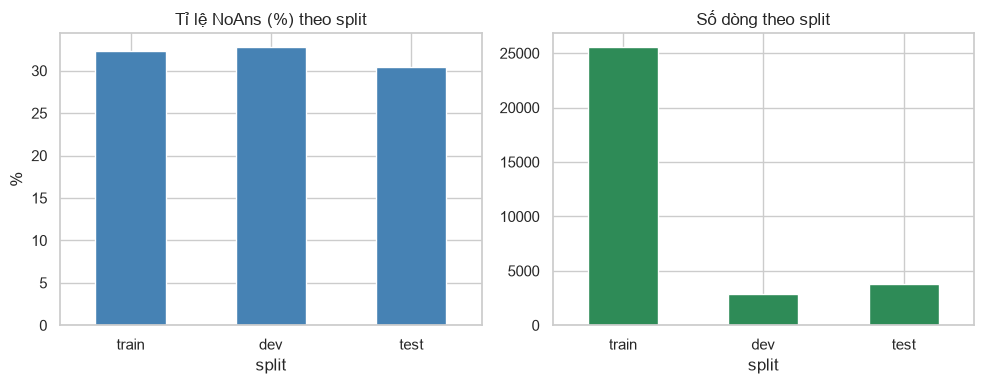

saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\outputs\figures\01_split.png


In [18]:
title_key = lambda r: r.get('title')
ctx_key = lambda r: normalize_text(r.get('context') or '')
for a, b in [('train', 'dev'), ('train', 'test'), ('dev', 'test')]:
    for name, kf in (('title', title_key), ('context', ctx_key)):
        shared = {kf(r) for r in SPLIT[a]} & {kf(r) for r in SPLIT[b]}
        # title overlap with validation was not verified beforehand: report it, do not assert
        if name == 'title' and 'test' in (a, b):
            print(f'title chung {a}/{b}: {len(shared)}')
            continue
        assert not shared, f'{name} overlap between {a} and {b}: {len(shared)}'
gap = abs(split_tbl.loc['dev', 'NoAns_%'] - split_tbl.loc['train', 'NoAns_%'])
assert gap <= 3, f'dev NoAns% differs from train by {gap:.2f} points'
print(f'OK: không trùng title/context giữa train/dev/test; chênh NoAns% dev vs train = {gap:.2f} điểm')

lab = split_tbl.loc[list(SPLIT)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
lab['NoAns_%'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Tỉ lệ NoAns (%) theo split')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=0)
lab['rows'].plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Số dòng theo split')
axes[1].tick_params(axis='x', rotation=0)
savefig('01_split.png')

In [19]:
def build_like(rs):
    return Dataset.from_list(rs, features=cd['train'].features)


split_dd = DatasetDict({'train': build_like(train_new), 'dev': build_like(dev),
                        'test': build_like(rows['validation']), 'test_unlabeled': build_like(UNLABELED)})
split_dir = PROC / 'uit_viquad2_split'
split_dd.save_to_disk(str(split_dir))
print(split_dd)

ids = {'train': [r['id'] for r in train_new], 'dev': [r['id'] for r in dev]}
with open(PROC / 'split_ids.json', 'w', encoding='utf-8') as f:
    json.dump(ids, f, ensure_ascii=False)
print('saved', split_dir, 'and', PROC / 'split_ids.json')

Saving the dataset (0/1 shards):   0%|          | 0/25542 [00:00<?, ? examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 25542/25542 [00:00<00:00, 1058386.23 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 25542/25542 [00:00<00:00, 1058386.23 examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2912 [00:00<?, ? examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 2912/2912 [00:00<00:00, 621093.99 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 2912/2912 [00:00<00:00, 510952.70 examples/s]

... (3 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/7301 [00:00<?, ? examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 7301/7301 [00:00<00:00, 863752.39 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 7301/7301 [00:00<00:00, 750903.94 examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 25542
    })
    dev: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 2912
    })
    test: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 3814
    })
    test_unlabeled: Dataset({
        features: ['id', 'uit_id', 'title', 'context', 'question', 'answers', 'is_impossible', 'plausible_answers'],
        num_rows: 7301
    })
})
saved D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\data\processed\uit_viquad2_split and D:\00_Workspace\AI_Lab\RAG_official\Extractive_QA\data\processed\split_ids.json


**Quy tắc: dev/test không quay lại train; test_new chấm một lần**